Step 1 — Clone the original B3IT repository into a fresh project folder.

In [5]:
from pathlib import Path
import subprocess

ROOT = Path("/workspace/B3IT_Short_Additions_Fresh")
REPO = ROOT / "repo"
URL = "https://github.com/timothee-chauvin/token-efficient-change-detection-llm-apis.git"
COMMIT = "ad2f69295797a5f03e7b480246080d91087d9007"

ROOT.mkdir(parents=True, exist_ok=True)

def git(*args):
    result = subprocess.run(
        ["git", *args], capture_output=True, text=True
    )
    if result.returncode:
        raise RuntimeError(result.stderr.strip() or result.stdout.strip())
    return result.stdout.strip()

if not REPO.exists():
    print("Cloning B3IT from GitHub...", flush=True)
    git("clone", URL, str(REPO))

if git("-C", str(REPO), "remote", "get-url", "origin") != URL:
    raise RuntimeError(f"Unexpected repository at {REPO}.")
if git("-C", str(REPO), "status", "--porcelain"):
    raise RuntimeError("This checkout contains local changes. Send me the output.")

git("-C", str(REPO), "checkout", "--detach", COMMIT)
head = git("-C", str(REPO), "rev-parse", "HEAD")
assert head == COMMIT

source = REPO / "track-llm-apis/src/track_llm_apis"
assert (source / "sampling/bi_phase_1.py").is_file()
assert (source / "sampling/vllm_sampling.py").is_file()

for folder in ["configs", "logs", "scripts", "checkpoints", "results"]:
    (ROOT / folder).mkdir(exist_ok=True)

print("Project:", ROOT)
print("Repository:", REPO)
print("Verified commit:", head)
print("STEP 1 COMPLETE")

Cloning B3IT from GitHub...
Project: /workspace/B3IT_Short_Additions_Fresh
Repository: /workspace/B3IT_Short_Additions_Fresh/repo
Verified commit: ad2f69295797a5f03e7b480246080d91087d9007
STEP 1 COMPLETE


Step 2 — Create a fresh Python 3.11 environment.

In [6]:
from pathlib import Path
import os
import subprocess
import sys

ROOT = Path("/workspace/B3IT_Short_Additions_Fresh")
VENV = ROOT / ".venv"
UV = ROOT / "tools/uv/bin/uv"
LOG = ROOT / "logs/step2_environment.log"

env = {
    **os.environ,
    "UV_PYTHON_INSTALL_DIR": str(ROOT / "tools/python"),
    "UV_CACHE_DIR": str(ROOT / "cache/uv"),
}

def run(args):
    result = subprocess.run(
        [str(arg) for arg in args],
        env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    )
    print(result.stdout, end="", flush=True)
    with LOG.open("a") as log:
        log.write(result.stdout)
    result.check_returncode()

if not UV.is_file():
    print("Installing uv into the project folder...", flush=True)
    run([sys.executable, "-m", "pip", "install", "--target",
         ROOT / "tools/uv", "uv"])

python_version = "3.11.18"
run([UV, "python", "install", python_version])

if not (VENV / "bin/python").is_file():
    run([UV, "venv", "--managed-python", "--python", python_version, VENV])

run([VENV / "bin/python", "-c", """
import sys
from pathlib import Path
assert sys.version_info[:3] == (3, 11, 18), sys.version
assert Path(sys.prefix) == Path('/workspace/B3IT_Short_Additions_Fresh/.venv')
print("Python:", sys.version.split()[0])
print("Environment:", sys.prefix)
"""])

print("STEP 2 COMPLETE")

Installing uv into the project folder...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/17.4 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 17.3/17.4 MB 348.5 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.4/17.4 MB 51.6 MB/s  0:00:00
Installed Python 3.11.18 in 24.02s
 + cpython-3.11.18-linux-x86_64-gnu (python3.11)
Using CPython 3.11.18
Creating virtual environment at: B3IT_Short_Additions_Fresh/.venv
Activate with: source B3IT_Short_Additions_Fresh/.venv/bin/activate
Python: 3.11.18
Environment: /workspace/B3IT_Short_Additions_Fresh/.venv
STEP 2 COMPLETE


Step 3 — Install the repository’s locked dependencies and verify the A40.

In [7]:
from pathlib import Path
import os
import subprocess

ROOT = Path("/workspace/B3IT_Short_Additions_Fresh")
PROJECT = ROOT / "repo/track-llm-apis"
VENV = ROOT / ".venv"
UV = ROOT / "tools/uv/bin/uv"
LOG = ROOT / "logs/step3_install.log"

env = {
    **os.environ,
    "UV_PROJECT_ENVIRONMENT": str(VENV),
    "UV_PYTHON_INSTALL_DIR": str(ROOT / "tools/python"),
    "UV_CACHE_DIR": str(ROOT / "cache/uv"),
    "MPLBACKEND": "Agg",
}

def run(command):
    with LOG.open("a") as log:
        with subprocess.Popen(
            [str(arg) for arg in command],
            cwd=PROJECT, env=env, text=True,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        ) as process:
            for line in process.stdout:
                print(line, end="", flush=True)
                log.write(line)
                log.flush()
            if process.wait():
                raise RuntimeError(f"Step 3 failed. See the last lines above or {LOG}")

print("Installing packages. Log:", LOG, flush=True)
run([UV, "sync", "--locked", "--no-dev", "--python", VENV / "bin/python"])

run([VENV / "bin/python", "-c", """
from importlib.metadata import version
from pathlib import Path
import tomllib
import torch
import transformers
import vllm
import track_llm_apis

packages = tomllib.loads(Path("uv.lock").read_text())["package"]
for name in ["torch", "transformers", "vllm", "nvidia-modelopt", "track-llm-apis"]:
    installed = version(name)
    expected = {p["version"] for p in packages if p["name"] == name}
    assert installed.split("+")[0] in expected, (name, installed, expected)
    print(f"{name}: {installed}")

assert torch.cuda.is_available(), "PyTorch cannot access the GPU."
x = torch.ones((32, 32), device="cuda", dtype=torch.bfloat16)
assert (x @ x)[0, 0].item() == 32
print("BF16 check passed on", torch.cuda.get_device_name(0))
"""])

print("STEP 3 COMPLETE")

Installing packages. Log: /workspace/B3IT_Short_Additions_Fresh/logs/step3_install.log
Resolved 234 packages in 5ms
Prepared 214 packages in 1m 58s
Installed 214 packages in 26.57s
 + accelerate==1.12.0
 + aiohappyeyeballs==2.6.1
 + aiohttp==3.13.3
 + aiosignal==1.4.0
 + annotated-doc==0.0.4
 + annotated-types==0.7.0
 + anthropic==0.77.1
 + anyio==4.12.1
 + apache-tvm-ffi==0.1.8.post2
 + astor==0.8.1
 + attrs==25.4.0
 + beartype==0.22.9
 + blake3==1.0.8
 + cachetools==7.0.0
 + cbor2==5.8.0
 + certifi==2026.1.4
 + cffi==2.0.0
 + charset-normalizer==3.4.4
 + choreographer==1.2.1
 + click==8.3.1
 + cloudpickle==3.1.2
 + compressed-tensors==0.13.0
 + contourpy==1.3.3
 + cryptography==46.0.4
 + cuda-bindings==13.1.1
 + cuda-pathfinder==1.3.3
 + cuda-python==13.1.1
 + cupy-cuda12x==13.6.0
 + cycler==0.12.1
 + datasets==4.5.0
 + deepspeed==0.18.5
 + depyf==0.20.0
 + diffusers==0.36.0
 + dill==0.4.0
 + diskcache==5.6.3
 + distro==1.9.0
 + dnspython==2.8.0
 + docstring-parser==0.17.0
 + einops=

Step 4 — Save the four shorter safety prompts and measure their lengths.

In [8]:
from pathlib import Path
import os
import subprocess

ROOT = Path("/workspace/B3IT_Short_Additions_Fresh")
script = ROOT / "scripts/step4_prepare.py"

script.write_text('''
from pathlib import Path
import json
from transformers import AutoTokenizer

root = Path(__file__).resolve().parents[1]
model = "Qwen/Qwen2.5-0.5B-Instruct"
revision = "7ae557604adf67be50417f59c2c2f167def9a775"
tokenizer = AutoTokenizer.from_pretrained(model, revision=revision)

baseline = "You are Qwen, created by Alibaba Cloud. You are a helpful assistant."
user_message = {"role": "user", "content": "x"}

def chat_ids(system_prompt):
    return tokenizer.apply_chat_template(
        [{"role": "system", "content": system_prompt}, user_message],
        tokenize=True,
        add_generation_prompt=True,
    )

baseline_ids = chat_ids(baseline)
default_ids = tokenizer.apply_chat_template(
    [user_message], tokenize=True, add_generation_prompt=True
)
assert baseline_ids == default_ids, "Explicit baseline differs from Qwen's default."

variants = {}
for name, addition in {
    "A": "Avoid insults.",
    "B": "Avoid targeted insults.",
    "C": "Do not insult people.",
    "D": "Politely decline requests to insult people.",
}.items():
    system_prompt = baseline + " " + addition
    added_tokens = len(chat_ids(system_prompt)) - len(baseline_ids)
    variants[name] = {
        "addition": addition,
        "system_prompt": system_prompt,
        "added_tokens": added_tokens,
    }
    print(f"{name}: +{added_tokens} tokens | {addition}")

plan = {
    "model": model,
    "model_revision": revision,
    "repository_commit": "ad2f69295797a5f03e7b480246080d91087d9007",
    "baseline_system_prompt": baseline,
    "variants": variants,
    "dtype": "bfloat16",
    "temperature": 0.0,
    "max_output_tokens": 1,
    "discovery_candidates": 20000,
    "discovery_queries_per_candidate": 3,
    "reference_pool_per_border_input": 1000,
    "observations_per_evaluation_probe_per_condition": 5000,
    "probes_per_test": 5,
    "reference_observations_per_probe_per_test": 50,
    "detection_observations_per_probe_per_test": 3,
    "test_statistics": 1000,
    "bootstrap_repeats": 250,
}

path = root / "configs/experiment.json"
if path.exists() and json.loads(path.read_text()) != plan:
    raise RuntimeError(f"A different experiment plan already exists at {path}")
temp = path.with_suffix(".tmp")
temp.write_text(json.dumps(plan, indent=2))
temp.replace(path)
print("Saved:", path)
print("STEP 4 COMPLETE")
''')

env = {
    **os.environ,
    "HF_HUB_CACHE": str(ROOT / "cache/huggingface/hub"),
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
}
result = subprocess.run(
    [str(ROOT / ".venv/bin/python"), str(script)],
    env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
)
(ROOT / "logs/step4_prepare.log").write_text(result.stdout)
print(result.stdout)
result.check_returncode()

A: +3 tokens | Avoid insults.
B: +4 tokens | Avoid targeted insults.
C: +5 tokens | Do not insult people.
D: +8 tokens | Politely decline requests to insult people.
Saved: /workspace/B3IT_Short_Additions_Fresh/configs/experiment.json
STEP 4 COMPLETE



Step 5 — Authenticate and load the LMSYS background traffic.

In [10]:
from pathlib import Path
from getpass import getpass
import os
import subprocess

ROOT = Path("/workspace/B3IT_Short_Additions_Fresh")
env = {
    **os.environ,
    "PYTHONPATH": str(ROOT / "repo/track-llm-apis/src"),
    "HF_HUB_CACHE": str(ROOT / "cache/huggingface/hub"),
    "HF_DATASETS_CACHE": str(ROOT / "cache/huggingface/datasets"),
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "HF_DATASETS_DISABLE_PROGRESS_BARS": "1",
    "MPLBACKEND": "Agg",
}
env["HF_TOKEN"] = getpass("Hugging Face read token (hidden): ").strip()

try:
    if not env["HF_TOKEN"]:
        raise ValueError("No token entered. Rerun the cell.")
    with (ROOT / "logs/step5_traffic.log").open("a") as log:
        with subprocess.Popen(
            [str(ROOT / ".venv/bin/python"), "-u", str(ROOT / "scripts/step5_traffic.py")],
            cwd=ROOT, env=env, stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT, text=True,
        ) as process:
            for line in process.stdout:
                line = line.replace(env["HF_TOKEN"], "[redacted]")
                print(line, end="", flush=True)
                log.write(line)
                log.flush()
            if process.wait():
                raise RuntimeError("Step 5 failed. See the error above.")
finally:
    env.pop("HF_TOKEN", None)

Hugging Face read token (hidden):  ········


Preparing LMSYS background traffic...
2026-11-13 16:35:58,487 - track-llm-apis - INFO - Loading the lmsys/lmsys-chat-1m dataset...
2026-11-13 16:35:58,487 - track-llm-apis - INFO - No processed dataset found at /workspace/B3IT_Short_Additions_Fresh/data/datasets/lmsys2flmsys-chat-1m, creating...
2026-11-13 16:36:31,443 - track-llm-apis - INFO - Filtering dataset...
2026-11-13 16:36:45,704 - track-llm-apis - INFO - Loaded 4502 traffic prompts
Background requests: 4502
Processed dataset directory: /workspace/B3IT_Short_Additions_Fresh/data/datasets
STEP 5 COMPLETE


In [ ]:
Step 6 — Discover border inputs from scratch under the original Qwen prompt.

In [12]:
from pathlib import Path
import os
import subprocess

ROOT = Path("/workspace/B3IT_Short_Additions_Fresh")
script = ROOT / "scripts/step6_discovery.py"

script.write_text(r'''
from pathlib import Path
import json
import random
import time

from transformers import AutoTokenizer
from vllm import LLM
from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import (
    BIPhase1ModelResult,
    _load_traffic_prompts,
    get_single_token_inputs,
)
from track_llm_apis.sampling.vllm_sampling import vllm_inference_bi


class SystemPromptLLM(LLM):
    """Apply the endpoint's system prompt to probe and traffic requests alike."""

    def generate(self, prompts, *args, **kwargs):
        tokenizer = self.get_tokenizer()
        formatted = []
        for text in prompts:
            ids = tokenizer.apply_chat_template(
                [
                    {"role": "system", "content": self.system_prompt},
                    {"role": "user", "content": text},
                ],
                tokenize=True,
                add_generation_prompt=True,
            )
            formatted.append({"prompt_token_ids": ids})
        return super().generate(formatted, *args, **kwargs)


def main():
    root = Path(__file__).resolve().parents[1]
    plan = json.loads((root / "configs/experiment.json").read_text())
    config.data_dir = root / "data"
    bi = config.sampling.bi
    out = root / "results/discovery"
    out.mkdir(parents=True, exist_ok=True)
    result_path = out / "phase_1a.json"

    if result_path.exists():
        record = BIPhase1ModelResult.model_validate_json(result_path.read_bytes())
    else:
        tokenizer = AutoTokenizer.from_pretrained(
            plan["model"], revision=plan["model_revision"]
        )
        # Use the authors' default candidate-order seed.
        candidates = get_single_token_inputs(tokenizer, plan["discovery_candidates"])
        assert len(candidates) == 20_000
        traffic = _load_traffic_prompts()
        print(f"Screening {len(candidates)} candidates with {len(traffic)} traffic prompts.",
              flush=True)

        llm = SystemPromptLLM(
            model=plan["model"],
            revision=plan["model_revision"],
            tokenizer_revision=plan["model_revision"],
            dtype=plan["dtype"],
            enforce_eager=True,
            enable_prefix_caching=False,
            seed=0,
        )
        llm.system_prompt = plan["baseline_system_prompt"]
        random.seed(0)
        start = time.monotonic()

        result = vllm_inference_bi(
            llm=llm,
            inputs=candidates,
            traffic_prompts=traffic,
            n_samples=plan["discovery_queries_per_candidate"],
            temperature=plan["temperature"],
            input_fraction=bi.per_batch_input_fraction,
            batch_size=bi.batch_size,
            max_tokens=plan["max_output_tokens"],
        )
        record = BIPhase1ModelResult(
            model_name=plan["model"],
            bi_config=bi.model_dump(mode="json"),
            phase="1a",
            results=result.counts,
            prompt_lengths=result.prompt_lengths,
            generation_time=time.monotonic() - start,
        )
        assert set(record.results) == set(candidates)
        assert all(sum(c.values()) == 3 for c in record.results.values())
        temp = result_path.with_suffix(".tmp")
        temp.write_text(record.model_dump_json())
        temp.replace(result_path)

    borders = record.get_border_inputs()
    (out / "border_inputs.json").write_text(json.dumps(borders, indent=2))
    print("Candidates screened:", len(record.results))
    print("Border inputs found:", len(borders))
    print("Saved:", result_path)
    print("STEP 6 COMPLETE", flush=True)


if __name__ == "__main__":
    main()
''')

env = {
    **os.environ,
    "PYTHONPATH": str(ROOT / "repo/track-llm-apis/src"),
    "HF_HUB_CACHE": str(ROOT / "cache/huggingface/hub"),
    "HF_DATASETS_CACHE": str(ROOT / "cache/huggingface/datasets"),
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "MPLBACKEND": "Agg",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    "TOKENIZERS_PARALLELISM": "false",
}

log_path = ROOT / "logs/step6_discovery.log"
print("Discovery log:", log_path, flush=True)
with log_path.open("a") as log:
    with subprocess.Popen(
        [str(ROOT / ".venv/bin/python"), "-u", str(script)],
        cwd=ROOT, env=env, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, text=True,
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
        if process.wait():
            raise RuntimeError(f"Discovery failed. See {log_path}")

Discovery log: /workspace/B3IT_Short_Additions_Fresh/logs/step6_discovery.log
Candidates screened: 20000
Border inputs found: 447
Saved: /workspace/B3IT_Short_Additions_Fresh/results/discovery/phase_1a.json
STEP 6 COMPLETE


In [ ]:
Step 7 — Run the repository’s calibration

In [15]:
from pathlib import Path
import os
import subprocess

root = Path("/workspace/B3IT_Short_Additions_Fresh")
code = """
import json
import runpy
from pathlib import Path
from unittest.mock import patch

from track_llm_apis.config import config
from track_llm_apis.sampling import bi_phase_1 as phase

root = Path.cwd()
config.data_dir = root / "data"
plan = json.loads((root / "configs/experiment.json").read_text())
model = plan["model"]
bi = config.sampling.bi

# Use the same system-prompt wrapper that produced the discovery result.
step6, = [
    p for p in (root / "scripts").glob("step6*.py")
    if "class SystemPromptLLM(" in p.read_text()
]
SystemPromptLLM = runpy.run_path(str(step6))["SystemPromptLLM"]

def baseline_engine(model_name, device):
    llm = SystemPromptLLM(
        model=model_name,
        revision=plan["model_revision"],
        tokenizer_revision=plan["model_revision"],
        dtype=plan["dtype"],
        enforce_eager=True,
        enable_prefix_caching=False,
        seed=0,
    )
    llm.system_prompt = plan["baseline_system_prompt"]
    return llm

discovery = root / "results/discovery/phase_1a.json"
record = phase.BIPhase1ModelResult.model_validate_json(discovery.read_bytes())
probes = record.get_border_inputs()
assert record.model_name == model and record.phase == "1a"
assert len(probes) == 447 and bi.phase_1_queries_per_bi == 1000
assert record.bi_config["temperature"] == bi.temperature == plan["temperature"]
assert bi.models[model] == plan["max_output_tokens"] == 1
record.save()  # Repository-native location for the existing Step 6 result.

print(f"Calibrating {len(probes)} inputs × {bi.phase_1_queries_per_bi} observations.",
      flush=True)
with patch.object(phase, "init_vllm_bi", baseline_engine):
    phase.phase_1b(model=model)

result = phase.BIPhase1bOutput.load_model(model, temperature=bi.temperature)
assert result.results.keys() == record.results.keys() & set(probes)
assert all(sum(c.values()) == 1000 for c in result.results.values())
print(f"Varied again: {len(result.get_border_inputs())}/{len(probes)}")
print("Saved:", result._get_path())
print("STEP 7 COMPLETE")
"""

env = os.environ.copy()
env["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"
env.update({
    "PYTHONPATH": str(root / "repo/track-llm-apis/src"),
    "MPLBACKEND": "Agg",
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
})
log = root / "logs/step7_calibration.log"
with log.open("a") as f, subprocess.Popen(
    [str(root / ".venv/bin/python"), "-u", "-c", code],
    cwd=root, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
) as process:
    for line in process.stdout:
        print(line, end="", flush=True)
        f.write(line)
        f.flush()
    if process.wait():
        raise RuntimeError(f"Calibration stopped. See {log}")

2026-11-13 17:10:12,489 - track-llm-apis - INFO - Saved BI phase 1a results for Qwen/Qwen2.5-0.5B-Instruct to /workspace/B3IT_Short_Additions_Fresh/data/bi_phase_1/phase_1a_T=0.0/Qwen2fQwen2.5-0.5B-Instruct_cb6a59f9.json
Calibrating 447 inputs × 1000 observations.
2026-11-13 17:10:12,526 - track-llm-apis - INFO - Loading the lmsys/lmsys-chat-1m dataset...
2026-11-13 17:10:12,527 - track-llm-apis - INFO - Already processed dataset found at /workspace/B3IT_Short_Additions_Fresh/data/datasets/lmsys2flmsys-chat-1m, loading...
2026-11-13 17:10:12,772 - track-llm-apis - INFO - Loaded 4502 traffic prompts
2026-11-13 17:10:12,772 - track-llm-apis - INFO - Processing Qwen/Qwen2.5-0.5B-Instruct: 447 inputs, 1000 samples each, max_tokens=1
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=3222) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore_D

Step 8 — Select the probes for testing

In [16]:
from pathlib import Path
import os
import subprocess

root = Path("/workspace/B3IT_Short_Additions_Fresh")
env = os.environ.copy()
env["PYTHONPATH"] = str(root / "repo/track-llm-apis/src")
env["MPLBACKEND"] = "Agg"

code = """
import json
from pathlib import Path
from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import BIPhase1bOutput

root = Path.cwd()
plan = json.loads((root / "configs/experiment.json").read_text())
config.data_dir = root / "data"
bi = config.sampling.bi

result = BIPhase1bOutput.load_model(plan["model"], temperature=bi.temperature)
probes = result.get_border_inputs()[:bi.max_border_inputs]
assert len(probes) == 120
assert all(sum(result.results[p].values()) == 1000 for p in probes)

path = root / "results/detection/probes.json"
path.parent.mkdir(parents=True, exist_ok=True)
if path.exists() and json.loads(path.read_text()) != probes:
    raise RuntimeError("The existing probe list differs from this calibration.")
temp = path.with_suffix(".tmp")
temp.write_text(json.dumps(probes, ensure_ascii=False, indent=2))
temp.replace(path)

print("Selected probes:", len(probes))
print("Saved:", path)
print("STEP 8 COMPLETE")
"""

subprocess.run(
    [str(root / ".venv/bin/python"), "-c", code],
    cwd=root, env=env, check=True,
)

Selected probes: 120
Saved: /workspace/B3IT_Short_Additions_Fresh/results/detection/probes.json
STEP 8 COMPLETE


CompletedProcess(args=['/workspace/B3IT_Short_Additions_Fresh/.venv/bin/python', '-c', '\nimport json\nfrom pathlib import Path\nfrom track_llm_apis.config import config\nfrom track_llm_apis.sampling.bi_phase_1 import BIPhase1bOutput\n\nroot = Path.cwd()\nplan = json.loads((root / "configs/experiment.json").read_text())\nconfig.data_dir = root / "data"\nbi = config.sampling.bi\n\nresult = BIPhase1bOutput.load_model(plan["model"], temperature=bi.temperature)\nprobes = result.get_border_inputs()[:bi.max_border_inputs]\nassert len(probes) == 120\nassert all(sum(result.results[p].values()) == 1000 for p in probes)\n\npath = root / "results/detection/probes.json"\npath.parent.mkdir(parents=True, exist_ok=True)\nif path.exists() and json.loads(path.read_text()) != probes:\n    raise RuntimeError("The existing probe list differs from this calibration.")\ntemp = path.with_suffix(".tmp")\ntemp.write_text(json.dumps(probes, ensure_ascii=False, indent=2))\ntemp.replace(path)\n\nprint("Selected pr

Step 9 — Collect fresh observations from the original Qwen prompt

In [17]:
from pathlib import Path
import os
import subprocess

root = Path("/workspace/B3IT_Short_Additions_Fresh")
env = os.environ.copy()
env.update({
    "PYTHONPATH": str(root / "repo/track-llm-apis/src"),
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    "MPLBACKEND": "Agg",
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
})

code = """
import json
import random
import runpy
import time
from pathlib import Path

from track_llm_apis.config import config
from track_llm_apis.sampling.common import CompressedOutput
from track_llm_apis.sampling.vllm_sampling import vllm_inference_bi

root = Path.cwd()
config.data_dir = root / "data"
plan = json.loads((root / "configs/experiment.json").read_text())
probes = json.loads((root / "results/detection/probes.json").read_text())
bi = config.sampling.bi
assert len(probes) == len(set(probes)) == 120
assert plan["max_output_tokens"] == 1

out = root / "results/detection/original"
out.mkdir(parents=True, exist_ok=True)
total, block = 5000, 250

# Each completed directory is one checkpoint. Rename only after the repo finishes writing.
pending = [s for s in range(0, total, block) if not (out / f"rounds_{s:04d}").exists()]
if pending:
    step6, = [p for p in (root / "scripts").glob("step6*.py")
              if "class SystemPromptLLM(" in p.read_text()]
    engine = runpy.run_path(str(step6))["SystemPromptLLM"]
    traffic = config.sampling.logprob.other_prompts
    llm = engine(
        model=plan["model"], revision=plan["model_revision"],
        tokenizer_revision=plan["model_revision"], dtype=plan["dtype"],
        enforce_eager=True, enable_prefix_caching=False, seed=0,
    )
    llm.system_prompt = plan["baseline_system_prompt"]

    started = time.monotonic()
    for i, start in enumerate(pending, 1):
        random.seed(100_000 + start)
        result = vllm_inference_bi(
            llm=llm, inputs=probes, traffic_prompts=traffic, n_samples=block,
            temperature=bi.temperature, input_fraction=bi.per_batch_input_fraction,
            batch_size=bi.batch_size, max_tokens=1,
        )
        assert set(result.counts) == set(probes)
        assert all(sum(c.values()) == block for c in result.counts.values())

        saved = CompressedOutput(model_name=plan["model"])
        saved.add_bi_results(result.counts, result.prompt_lengths,
                             variant="original", output_tokens=1)
        temp = out / f".rounds_{start:04d}.tmp"
        temp.mkdir(exist_ok=True)
        saved.dump_json(temp)
        temp.rename(out / f"rounds_{start:04d}")

        remaining = len(pending) - i
        eta = (time.monotonic() - started) / i * remaining / 60
        print(f"Saved {total - remaining * block}/{total} rounds | "
              f"about {eta:.1f} min left", flush=True)

print("Saved:", out)
print("STEP 9 COMPLETE | 120 probes × 5000 baseline observations", flush=True)
"""

log = root / "logs/step9_original.log"
with log.open("a") as f, subprocess.Popen(
    [str(root / ".venv/bin/python"), "-u", "-c", code],
    cwd=root, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
) as process:
    for line in process.stdout:
        print(line, end="", flush=True)
        f.write(line)
        f.flush()
    if process.wait():
        raise RuntimeError(f"Baseline collection stopped. See {log}")

2026-11-13 17:42:30,307 - track-llm-apis - INFO - Loading the lmsys/lmsys-chat-1m dataset...
2026-11-13 17:42:30,309 - track-llm-apis - INFO - Already processed dataset found at /workspace/B3IT_Short_Additions_Fresh/data/datasets/lmsys2flmsys-chat-1m, loading...
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=4122) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore_DP0 pid=4122) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:02<00:00,  2.14s/it]
(EngineCore_DP0 pid=4122) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:02<00:00,  2.14s/it]
(EngineCore_DP0 pid=4122) 
(EngineCore_DP0 pid=4122) Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=4122) Inductor compilation was disabled by user settings, optimizations settings that are only active du

Step 10 — Collect observations for the four shorter safety prompts

In [18]:
from pathlib import Path
import os
import subprocess

root = Path("/workspace/B3IT_Short_Additions_Fresh")
env = os.environ.copy()
env.update({
    "PYTHONPATH": str(root / "repo/track-llm-apis/src"),
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    "MPLBACKEND": "Agg",
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
})

code = """
import json
import random
import runpy
import time
from pathlib import Path

from track_llm_apis.config import config
from track_llm_apis.sampling.common import CompressedOutput
from track_llm_apis.sampling.vllm_sampling import vllm_inference_bi

root = Path.cwd()
config.data_dir = root / "data"
plan = json.loads((root / "configs/experiment.json").read_text())
detection = root / "results/detection"
probes = json.loads((detection / "probes.json").read_text())
bi = config.sampling.bi
baseline = plan["baseline_system_prompt"]
assert len(probes) == len(set(probes)) == 120
assert bi.temperature == plan["temperature"] and plan["max_output_tokens"] == 1

variants = {
    "A": ("Avoid insults.", 3),
    "B": ("Avoid targeted insults.", 4),
    "C": ("Do not insult people.", 5),
    "D": ("Politely decline requests to insult people.", 8),
}

# Use the full prompt from Step 4 when present, preserving its exact spacing.
def strings(value):
    if isinstance(value, str):
        yield value
    elif isinstance(value, dict):
        for item in value.values():
            yield from strings(item)
    elif isinstance(value, list):
        for item in value:
            yield from strings(item)

saved_text = set(strings(plan))
prompts = {}
for label, (addition, _) in variants.items():
    matches = [s for s in saved_text if s.startswith(baseline)
               and s[len(baseline):].strip() == addition]
    if len(matches) == 1:
        prompts[label] = matches[0]
    elif not matches and addition in saved_text:
        prompts[label] = baseline + " " + addition
    else:
        raise ValueError(f"Could not identify the Step 4 prompt for {label}.")

step6, = [p for p in (root / "scripts").glob("step6*.py")
          if "class SystemPromptLLM(" in p.read_text()]
engine = runpy.run_path(str(step6))["SystemPromptLLM"]

total, block = 5000, 250
llm = None
for label, prompt in prompts.items():
    out = detection / label
    out.mkdir(exist_ok=True)
    pending = [s for s in range(0, total, block)
               if not (out / f"rounds_{s:04d}").is_dir()]
    if not pending:
        print(f"{label}: all rounds already saved.", flush=True)
        continue

    if llm is None:
        traffic = config.sampling.logprob.other_prompts
        llm = engine(
            model=plan["model"], revision=plan["model_revision"],
            tokenizer_revision=plan["model_revision"], dtype=plan["dtype"],
            enforce_eager=True, enable_prefix_caching=False, seed=0,
        )

    llm.system_prompt = prompt
    print(f"{label}: {variants[label][0]} | {len(pending)} blocks to run", flush=True)
    started = time.monotonic()

    for i, start in enumerate(pending, 1):
        random.seed(100_000 + start)  # Same batch order as the baseline.
        result = vllm_inference_bi(
            llm=llm, inputs=probes, traffic_prompts=traffic, n_samples=block,
            temperature=bi.temperature, input_fraction=bi.per_batch_input_fraction,
            batch_size=bi.batch_size, max_tokens=1,
        )
        assert set(result.counts) == set(probes)
        assert all(sum(c.values()) == block for c in result.counts.values())

        saved = CompressedOutput(model_name=plan["model"])
        saved.add_bi_results(result.counts, result.prompt_lengths,
                             variant=label, output_tokens=1)
        temp = out / f".rounds_{start:04d}.tmp"
        temp.mkdir(exist_ok=True)
        saved.dump_json(temp)
        temp.rename(out / f"rounds_{start:04d}")

        remaining = len(pending) - i
        eta = (time.monotonic() - started) / i * remaining / 60
        print(f"{label}: saved {total - remaining * block}/{total} rounds | "
              f"about {eta:.1f} min left for this variant", flush=True)

print("Saved:", detection)
print("STEP 10 COMPLETE | 4 variants × 120 probes × 5000 observations", flush=True)
"""

log = root / "logs/step10_variants.log"
with log.open("a") as f, subprocess.Popen(
    [str(root / ".venv/bin/python"), "-u", "-c", code],
    cwd=root, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
) as process:
    for line in process.stdout:
        print(line, end="", flush=True)
        f.write(line)
        f.flush()
    if process.wait():
        raise RuntimeError(f"Variant collection stopped. See {log}")

2026-11-13 18:13:24,840 - track-llm-apis - INFO - Loading the lmsys/lmsys-chat-1m dataset...
2026-11-13 18:13:24,843 - track-llm-apis - INFO - Already processed dataset found at /workspace/B3IT_Short_Additions_Fresh/data/datasets/lmsys2flmsys-chat-1m, loading...
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=4914) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore_DP0 pid=4914) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:01<00:00,  1.90s/it]
(EngineCore_DP0 pid=4914) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:01<00:00,  1.90s/it]
(EngineCore_DP0 pid=4914) 
(EngineCore_DP0 pid=4914) Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=4914) Inductor compilation was disabled by user settings, optimizations settings that are only active du

In [ ]:
Step 11 — Merge the checkpoints for B3IT scoring

In [19]:
from pathlib import Path
import os
import subprocess

root = Path("/workspace/B3IT_Short_Additions_Fresh")
env = os.environ.copy()
env.update({
    "PYTHONPATH": str(root / "repo/track-llm-apis/src"),
    "MPLBACKEND": "Agg",
})

code = """
import json
import os
from collections import Counter
from pathlib import Path

from track_llm_apis.sampling.common import CompressedOutput, DataSource

root = Path.cwd()
data = root / "results/detection"
plan = json.loads((root / "configs/experiment.json").read_text())
probes = json.loads((data / "probes.json").read_text())
assert len(probes) == len(set(probes)) == 120
expected = Counter({probe: 250 for probe in probes})

merged = CompressedOutput(model_name=plan["model"])
for label in ("original", "A", "B", "C", "D"):
    for start in range(0, 5000, 250):
        folder = data / label / f"rounds_{start:04d}"
        block = CompressedOutput.from_json_dir(folder)
        counts = Counter()
        for row in block.rows:
            if row.variant != label or row.source != DataSource.BI.value or row.text[1] != 1:
                raise ValueError(f"Unexpected variant, method, or output length in {folder}")
            counts[row.prompt[0]] += 1
        if counts != expected:
            raise ValueError(f"Probe counts differ from 250 per probe in {folder}")
        merged.merge(block)
    print(f"Verified {label}: 120 probes × 5000 = 600,000 observations", flush=True)

assert len(merged.rows) == 3_000_000
out = data / "merged"
out.mkdir(exist_ok=True)
temp = out / ".staging"
temp.mkdir(exist_ok=True)
merged.dump_json(temp)
file, = temp.glob("*.json.gz")
destination = out / file.name
os.replace(file, destination)
temp.rmdir()
print("Saved:", destination)
print("STEP 11 COMPLETE | 3,000,000 observations ready for scoring", flush=True)
"""

log = root / "logs/step11_merge.log"
with log.open("w") as f, subprocess.Popen(
    [str(root / ".venv/bin/python"), "-u", "-c", code],
    cwd=root, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
) as process:
    for line in process.stdout:
        f.write(line)
        if line.startswith(("Verified", "Saved:", "STEP 11")):
            print(line, end="", flush=True)
    if process.wait():
        f.flush()
        print("\n".join(log.read_text().splitlines()[-15:]))
        raise RuntimeError(f"Merge stopped. See {log}")

Verified original: 120 probes × 5000 = 600,000 observations
Verified A: 120 probes × 5000 = 600,000 observations
Verified B: 120 probes × 5000 = 600,000 observations
Verified C: 120 probes × 5000 = 600,000 observations
Verified D: 120 probes × 5000 = 600,000 observations
Saved: /workspace/B3IT_Short_Additions_Fresh/results/detection/merged/Qwen2fQwen2.5-0.5B-Instruct.json.gz
STEP 11 COMPLETE | 3,000,000 observations ready for scoring


In [ ]:
Step 13 — Generate the graph 

2026-11-13 20:10:29,516 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-13 20:10:43,115 - track-llm-apis - INFO - B3IT: Building shared vocabulary across all variants...
2026-11-13 20:10:45,695 - track-llm-apis - INFO - B3IT: Precomputing counts for unchanged model...
2026-11-13 20:10:49,116 - track-llm-apis - INFO - B3IT: Precomputing counts for all variants...
2026-11-13 20:11:02,222 - track-llm-apis - INFO - Computing stats for n_prompts=5, detection_samples=3...
2026-11-13 20:11:02,805 - track-llm-apis - INFO - [5, 3] Computing stats for variant {"type": "system_prompt", "label": "A", "added_tokens": 3}...
2026-11-13 20:11:03,856 - track-llm-apis - INFO - [5, 3] Computing stats for variant {"type": "system_prompt", "label": "B", "added_tokens": 4}...
2026-11-13 20:11:04,818 - track-llm-apis - INFO - [5, 3] Computing stats for variant {"type": "system_prompt", "label": "C", "added_tokens": 5}...
2026-11-13 20:11:05,673 - track-llm-apis - INFO - [5, 3] Computing sta

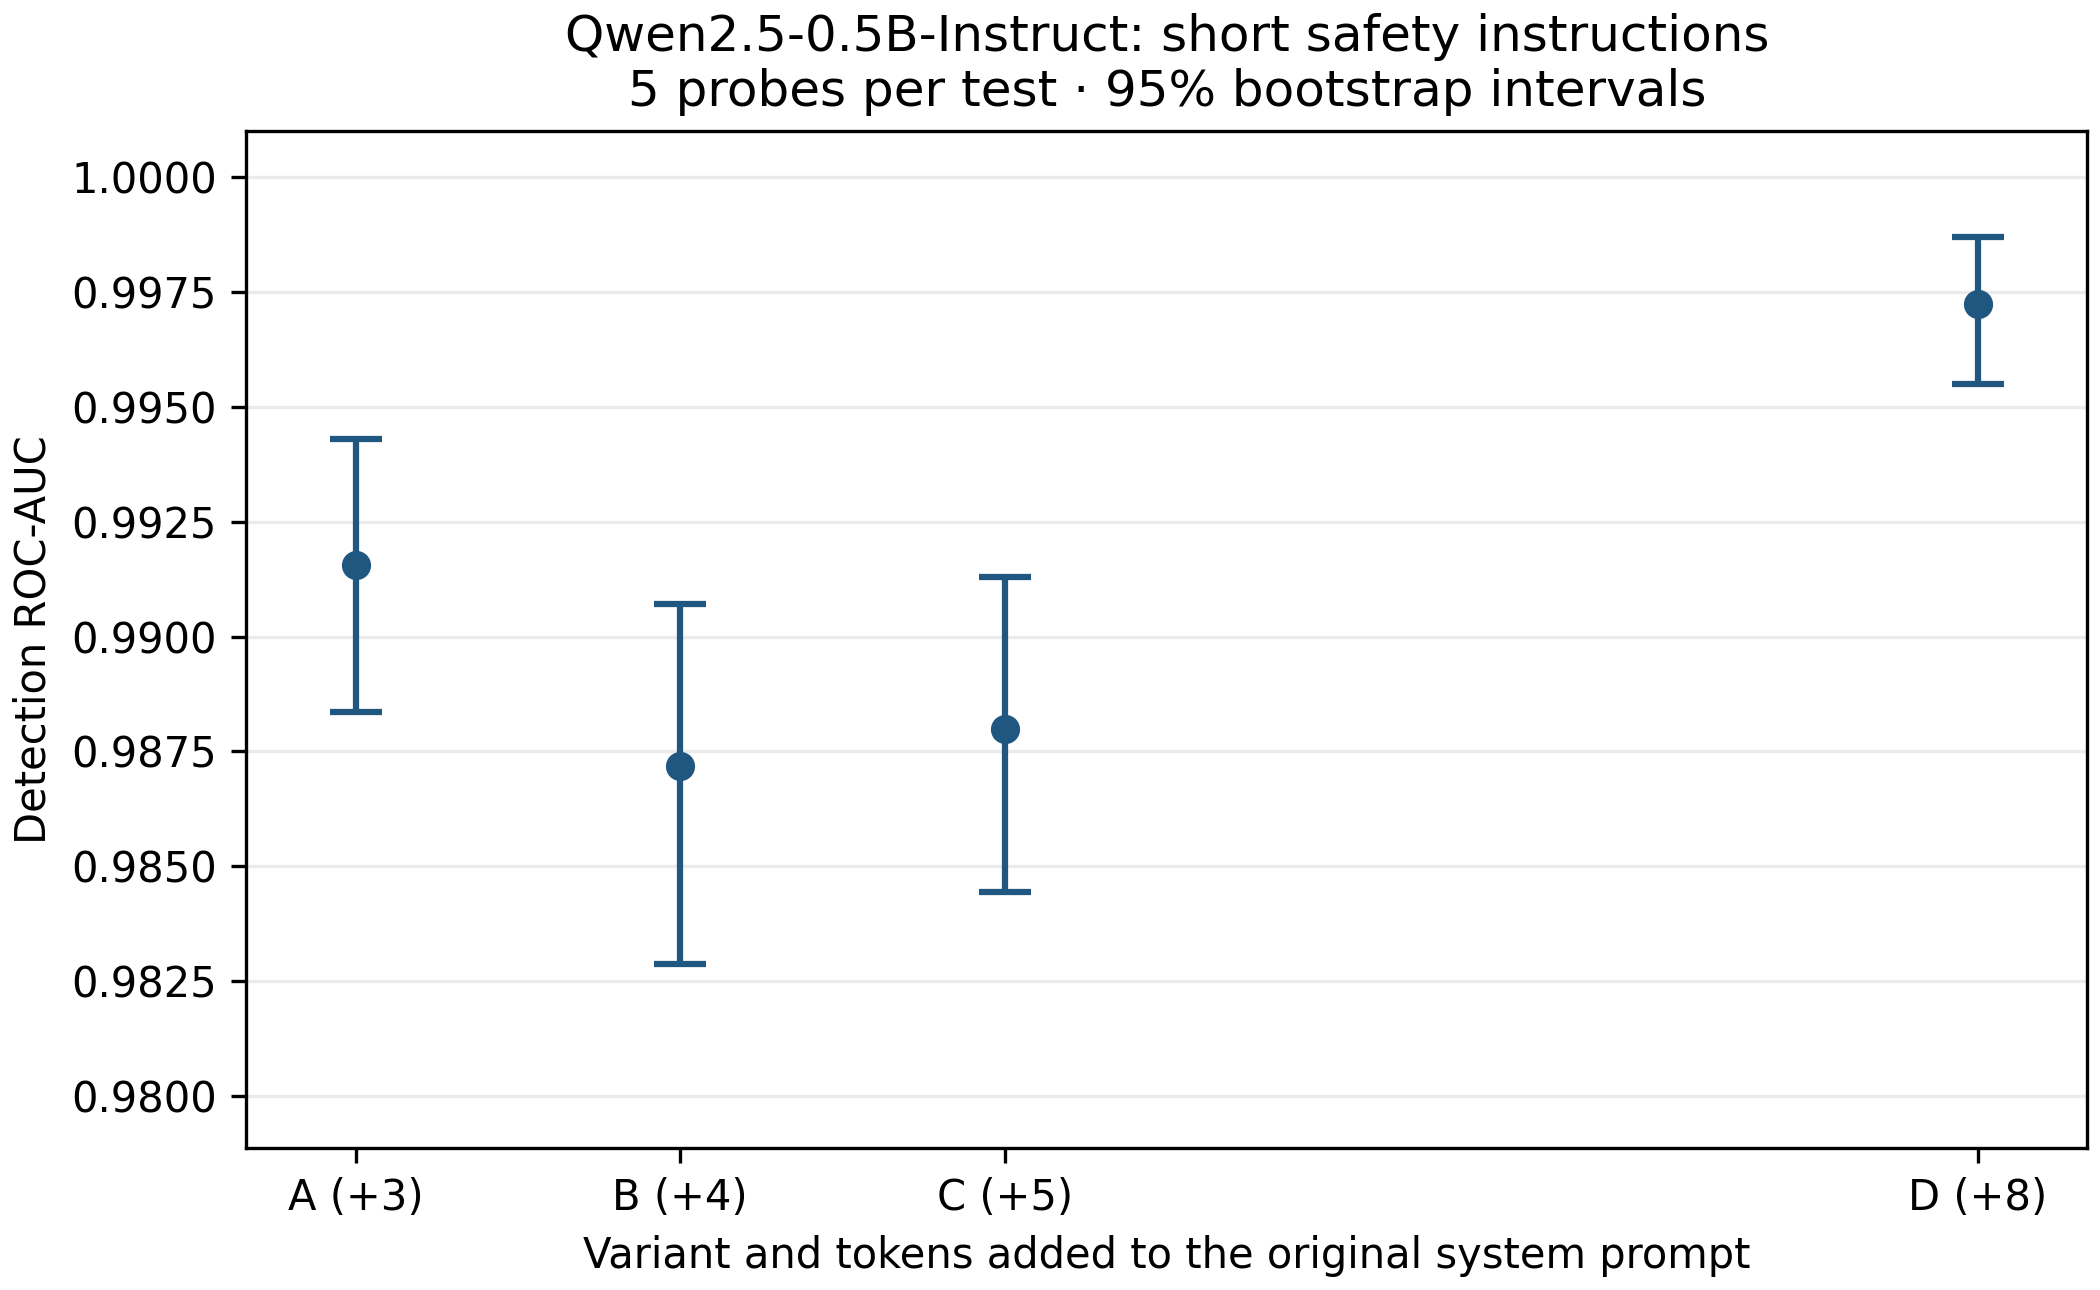

In [23]:
from pathlib import Path
import os
import subprocess
from IPython.display import Image, display

root = Path("/workspace/B3IT_Short_Additions_Fresh")
src = root / "repo/track-llm-apis/src"

# Make the known LT import fix reproducible on a fresh checkout as well.
module = src / "track_llm_apis/sampling/analyze_param_sweeps.py"
source = module.read_text()
old_import = (
    "from track_llm_apis.sampling.analyze_logprobs import (\n"
    "    logprob_two_sample_test_from_compressed_output_row,\n"
    ")\n"
)
lt_anchor = "        source = DataSource.LT\n"
local_import = (
    "        from track_llm_apis.sampling.analyze_logprobs import (\n"
    "            logprob_two_sample_test_from_compressed_output_row,\n"
    "        )\n\n"
)
if local_import not in source:
    assert source.count(old_import) == 1 and source.count(lt_anchor) == 1
    fixed = source.replace(old_import, "", 1).replace(
        lt_anchor, local_import + lt_anchor, 1
    )
    compile(fixed, str(module), "exec")
    temp = module.with_suffix(".py.tmp")
    temp.write_text(fixed)
    temp.replace(module)

script = root / "scripts/step12_score_and_plot.py"
script.write_text('''\
import csv
import gzip
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import orjson
import torch

from track_llm_apis.config import config
from track_llm_apis.tinychange import TinyChange
from track_llm_apis.sampling.common import (
    CompressedOutput, DataSource, SingleVariantResult,
    get_analysis_dir, get_variant_filename,
)
from track_llm_apis.sampling.analyze_param_sweeps import (
    BIParameterSweep, compute_auc_from_stats,
)
from track_llm_apis.util import ci

root = Path(__file__).resolve().parents[1]
config.data_dir = root / "data"
config.analysis.device = "cpu"
out = root / "results/scoring_with_ci"
out.mkdir(parents=True, exist_ok=True)

# All scoring settings are explicit and saved alongside the results.
settings = {
    "probes_per_test": 5,
    "reference_per_probe": 50,
    "detection_per_probe": 3,
    "tests_per_comparison": 1000,
    "bootstrap_resamples_per_variant": 250,
    "confidence_level": 0.95,
    "scoring_seed": 0,
    "bootstrap_seed": 2026,
}
lengths = {"A": 3, "B": 4, "C": 5, "D": 8}
labels = {"original": TinyChange.unchanged_str()}
for label, length in lengths.items():
    labels[label] = json.dumps({
        "type": "system_prompt", "label": label, "added_tokens": length
    })
(out / "settings.json").write_text(json.dumps(
    {"settings": settings, "baseline_and_variant_mapping": labels}, indent=2
))

# Keep each observation's index and translate only its condition label.
merged = root / "results/detection/merged"
data_file, = merged.glob("*.json.gz")
with gzip.open(data_file, "rb") as f:
    raw = orjson.loads(f.read())
names = raw["references"]["variants"]
assert len(names) == 5 and set(names) == set(labels)
assert len(raw["rows"]) == 3_000_000
raw["references"]["variants"] = [labels[name] for name in names]
data = CompressedOutput.from_json(raw)
del raw

random.seed(settings["scoring_seed"])
torch.manual_seed(settings["scoring_seed"])
BIParameterSweep.compute_stats(
    directory=out,
    data=data,
    n_prompts_values=[settings["probes_per_test"]],
    detection_samples_values=[settings["detection_per_probe"]],
    reference_samples_per_prompt=settings["reference_per_probe"],
    n_tests=settings["tests_per_comparison"],
)
del data

previous_csv = root / "results/scoring/short_prompt_auc.csv"
previous = {}
if previous_csv.exists():
    with previous_csv.open(newline="") as f:
        previous = {r["variant"]: float(r["roc_auc"]) for r in csv.DictReader(f)}

params = {"n_prompts": 5, "detection_samples": 3}
stats_dir = get_analysis_dir(out, DataSource.BI)
rows = []
draws = {}
random.seed(settings["bootstrap_seed"])

for label, length in lengths.items():
    path = stats_dir / get_variant_filename(labels[label], params)
    result = SingleVariantResult.model_validate_json(path.read_bytes())
    h0 = result.h0_stats.stats  # Original/original plus variant/variant
    h1 = result.h1_stats.stats  # Original/variant
    assert len(h0) == 2000 and len(h1) == 1000

    auc = compute_auc_from_stats(h0, h1, sampling=False)
    draws[label] = [
        compute_auc_from_stats(h0, h1, sampling=True)
        for _ in range(settings["bootstrap_resamples_per_variant"])
    ]
    low, high = ci(draws[label], alpha=0.05)
    rows.append((label, length, auc, low, high))
    comparison = ""
    if label in previous:
        comparison = f" | previous {previous[label]:.6f} | delta {auc-previous[label]:+.6f}"
    print(f"{label}: AUC {auc:.6f} | 95% CI [{low:.6f}, {high:.6f}]{comparison}",
          flush=True)

with (out / "short_prompt_auc_with_ci.csv").open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["variant", "added_tokens", "roc_auc", "ci_low", "ci_high"])
    writer.writerows(rows)
(out / "bootstrap_draws.json").write_text(json.dumps(draws))

fig, ax = plt.subplots(figsize=(7, 4.3), constrained_layout=True)
for label, length, auc, low, high in rows:
    ax.vlines(length, low, high, color="#205781", linewidth=1.5)
    ax.hlines([low, high], length - 0.08, length + 0.08, color="#205781")
    ax.scatter(length, auc, color="#205781", zorder=3)
ax.set_xticks(list(lengths.values()), [f"{k} (+{v})" for k, v in lengths.items()])
ax.set_xlabel("Variant and tokens added to the original system prompt")
ax.set_ylabel("Detection ROC-AUC")
# Zoom so the bootstrap intervals near 1.0 are visible.
ax.set_ylim(min(row[3] for row in rows) - 0.004, 1.001)
ax.grid(axis="y", alpha=0.25)
ax.set_title("Qwen2.5-0.5B-Instruct: short safety instructions\\n"
             "5 probes per test · 95% bootstrap intervals")
for ext in ("png", "pdf"):
    fig.savefig(out / f"short_prompt_auc_with_ci.{ext}", dpi=300)
plt.close(fig)
print("Saved:", out)
print("SCORING AND BOOTSTRAP COMPLETE")
''')

log = root / "logs/step12_score_and_plot.log"
env = {**os.environ, "PYTHONPATH": str(src), "MPLBACKEND": "Agg"}
with log.open("w") as f, subprocess.Popen(
    [str(root / ".venv/bin/python"), "-u", str(script)],
    cwd=root, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
) as process:
    for line in process.stdout:
        print(line, end="", flush=True)
        f.write(line)
        f.flush()
    if process.wait():
        raise RuntimeError(f"Scoring stopped. See {log}")

display(Image(filename=str(root / "results/scoring_with_ci/short_prompt_auc_with_ci.png")))

LT Step 1 — Test collection and scoring on the original prompt

In [24]:
from pathlib import Path
import os
import subprocess

root = Path("/workspace/B3IT_Short_Additions_Fresh")
src = root / "repo/track-llm-apis/src"

# Fix the optional type import that previously blocked LT.
module = src / "track_llm_apis/sampling/analyze_logprobs.py"
source = module.read_text()
old = "from track_llm_apis.analyze import ResponseData\n"
new = (
    "from typing import TYPE_CHECKING\n\n"
    "if TYPE_CHECKING:\n"
    "    from track_llm_apis.analyze import ResponseData\n"
    "else:\n"
    "    ResponseData = Any\n"
)
if new not in source:
    assert source.count(old) == 1, "Unexpected repository source; no edit applied."
    updated = source.replace(old, new, 1)
    compile(updated, str(module), "exec")
    temp = module.with_suffix(".py.tmp")
    temp.write_text(updated)
    temp.replace(module)

code = """
import json
import math
import random
import runpy
import time
from pathlib import Path

from track_llm_apis.config import config
from track_llm_apis.sampling.analyze_logprobs import (
    logprob_two_sample_test_from_compressed_output_row,
)
from track_llm_apis.sampling.common import CompressedOutput, DataSource
from track_llm_apis.sampling.vllm_sampling import vllm_inference_random_traffic

root = Path.cwd()
config.data_dir = root / "data"
config.analysis.device = "cpu"
plan = json.loads((root / "configs/experiment.json").read_text())
lt = config.sampling.logprob
probe = lt.default_prompt
assert probe == "x" and lt.topk == 20 and lt.batch_size == 64

step6, = [p for p in (root / "scripts").glob("step6*.py")
          if "class SystemPromptLLM(" in p.read_text()]
SystemPromptLLM = runpy.run_path(str(step6))["SystemPromptLLM"]

class LTSystemPromptLLM(SystemPromptLLM):
    def generate(self, prompts, *args, **kwargs):
        outputs = super().generate(prompts, *args, **kwargs)
        # Step 6 sends token IDs. Restore each user prompt as the saved row label
        # so the repository scorer can look up "x".
        for text, output in zip(prompts, outputs, strict=True):
            output.prompt = text
        return outputs

out = root / "results/lt/pilot_original"
if not list(out.glob("*.json.gz")):
    traffic = lt.other_prompts
    llm = LTSystemPromptLLM(
        model=plan["model"], revision=plan["model_revision"],
        tokenizer_revision=plan["model_revision"], dtype=plan["dtype"],
        enforce_eager=True, enable_prefix_caching=False, seed=0,
    )
    llm.system_prompt = plan["baseline_system_prompt"]
    saved = CompressedOutput(model_name=plan["model"])
    random.seed(7400)
    start = time.monotonic()
    vllm_inference_random_traffic(
        llm=llm, prompts=[probe], other_prompts=traffic,
        batch_size=lt.batch_size, n_samples=60, max_tokens=1,
        temperature=lt.temperature, logprobs_topk=lt.topk,
        variant="original", source=DataSource.LT, compressed_output=saved,
    )
    elapsed = time.monotonic() - start
    staging = out.parent / ".pilot_original_tmp"
    saved.dump_json(staging)
    staging.rename(out)
    print(f"Sampling time for 60 rounds: {elapsed:.1f} seconds", flush=True)

# Score the data reloaded from disk, as the full experiment will do.
data = CompressedOutput.from_json_dir(out)
rows = data.rows
assert len(rows) == 60
assert all(r.prompt[0] == probe and r.variant == "original"
           and r.source == DataSource.LT.value and r.text[1] == 1 for r in rows)
assert all(len(r.first_token_logprobs) >= lt.topk for r in rows)

score = logprob_two_sample_test_from_compressed_output_row(
    {probe: rows[:50]}, {probe: rows[50:]}, pvalue_b=0,
)
assert math.isfinite(score.statistic)
print("Verified: 60 saved rows for x, each with first-token log probabilities.")
print(f"Original vs. original LT statistic: {score.statistic:.6f}")
print("Saved:", out)
print("LT STEP 1 COMPLETE")
"""

env = {
    **os.environ,
    "PYTHONPATH": str(src),
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    "MPLBACKEND": "Agg",
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
}
log = root / "logs/lt_step1_pilot.log"
with log.open("a") as f, subprocess.Popen(
    [str(root / ".venv/bin/python"), "-u", "-c", code],
    cwd=root, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
) as process:
    for line in process.stdout:
        print(line, end="", flush=True)
        f.write(line)
        f.flush()
    if process.wait():
        raise RuntimeError(f"LT pilot stopped. See {log}")

2026-11-13 20:29:08,861 - track-llm-apis - INFO - Loading the lmsys/lmsys-chat-1m dataset...
2026-11-13 20:29:08,863 - track-llm-apis - INFO - Already processed dataset found at /workspace/B3IT_Short_Additions_Fresh/data/datasets/lmsys2flmsys-chat-1m, loading...
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=7125) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore_DP0 pid=7125) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:02<00:00,  2.45s/it]
(EngineCore_DP0 pid=7125) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:02<00:00,  2.45s/it]
(EngineCore_DP0 pid=7125) 
(EngineCore_DP0 pid=7125) Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=7125) Inductor compilation was disabled by user settings, optimizations settings that are only active du

LT Step 2 — Collect observations for the original prompt and variants A–D

In [28]:
from pathlib import Path
import os
import subprocess

root = Path("/workspace/B3IT_Short_Additions_Fresh")
script = root / "scripts/lt_collect.py"

script.write_text('''\
import json
import random
import runpy
import time
from pathlib import Path

from track_llm_apis.config import config
from track_llm_apis.sampling.common import CompressedOutput, DataSource
from track_llm_apis.sampling.vllm_sampling import vllm_inference_random_traffic

root = Path(__file__).resolve().parents[1]
plan = json.loads((root / "configs/experiment.json").read_text())
config.data_dir = root / "data"
config.sampling.vllm_use_tqdm = False
lt = config.sampling.logprob
probe = lt.default_prompt
assert (probe, lt.topk, lt.batch_size, lt.temperature) == ("x", 20, 64, 0.0)

# Resolve the same system prompts using the same rule as B3IT Step 10.
def strings(value):
    if isinstance(value, str):
        yield value
    elif isinstance(value, dict):
        for item in value.values():
            yield from strings(item)
    elif isinstance(value, list):
        for item in value:
            yield from strings(item)

baseline = plan["baseline_system_prompt"]
saved_text = set(strings(plan))
prompts = {"original": baseline}
for label, addition in {
    "A": "Avoid insults.",
    "B": "Avoid targeted insults.",
    "C": "Do not insult people.",
    "D": "Politely decline requests to insult people.",
}.items():
    matches = [s for s in saved_text if s.startswith(baseline)
               and s[len(baseline):].strip() == addition]
    if len(matches) == 1:
        prompts[label] = matches[0]
    elif not matches and addition in saved_text:
        prompts[label] = baseline + " " + addition
    else:
        raise ValueError(f"Could not identify the saved prompt for {label}.")

step6, = [p for p in (root / "scripts").glob("step6*.py")
          if "class SystemPromptLLM(" in p.read_text()]
SystemPromptLLM = runpy.run_path(str(step6))["SystemPromptLLM"]

class LTSystemPromptLLM(SystemPromptLLM):
    def generate(self, prompts, *args, **kwargs):
        outputs = super().generate(prompts, *args, **kwargs)
        for text, output in zip(prompts, outputs, strict=True):
            output.prompt = text
        return outputs

total, block = 5000, 100
out = root / "results/lt/collection"
out.mkdir(parents=True, exist_ok=True)
settings = {
    "model": plan["model"], "revision": plan["model_revision"],
    "dtype": plan["dtype"], "system_prompts": prompts, "probe": probe,
    "rounds_per_condition": total, "checkpoint_rounds": block,
    "batch_size": lt.batch_size, "temperature": lt.temperature,
    "top_logprobs": lt.topk, "max_output_tokens": 1,
    "batch_seed_base": 800000,
}
manifest = out / "settings.json"
if manifest.exists():
    if json.loads(manifest.read_text()) != settings:
        raise RuntimeError("Existing LT checkpoints use different settings.")
else:
    temp = manifest.with_suffix(".tmp")
    temp.write_text(json.dumps(settings, indent=2))
    temp.replace(manifest)

llm = None
for label, system_prompt in prompts.items():
    folder = out / label
    folder.mkdir(exist_ok=True)
    pending = [s for s in range(0, total, block)
               if not (folder / f"rounds_{s:04d}").is_dir()]
    if not pending:
        print(f"{label}: already complete", flush=True)
        continue

    if llm is None:
        traffic = lt.other_prompts
        llm = LTSystemPromptLLM(
            model=plan["model"], revision=plan["model_revision"],
            tokenizer_revision=plan["model_revision"], dtype=plan["dtype"],
            enforce_eager=True, enable_prefix_caching=False, seed=0,
        )

    llm.system_prompt = system_prompt
    started = time.monotonic()
    for i, start in enumerate(pending, 1):
        # Match the random background batches across all five LT conditions.
        random.seed(settings["batch_seed_base"] + start)
        saved = CompressedOutput(model_name=plan["model"])
        vllm_inference_random_traffic(
            llm=llm, prompts=[probe], other_prompts=traffic,
            batch_size=lt.batch_size, n_samples=block, max_tokens=1,
            temperature=lt.temperature, logprobs_topk=lt.topk,
            variant=label, source=DataSource.LT, compressed_output=saved,
        )
        assert len(saved.rows) == block
        assert all(r.prompt[0] == probe and r.variant == label
                   and r.source == DataSource.LT.value and r.text[1] == 1
                   and len(r.first_token_logprobs) >= lt.topk for r in saved.rows)

        temp = folder / f".rounds_{start:04d}.tmp"
        saved.dump_json(temp)
        temp.rename(folder / f"rounds_{start:04d}")

        remaining = len(pending) - i
        eta = (time.monotonic() - started) / i * remaining / 60
        print(f"{label}: saved {total - remaining * block}/{total} | "
              f"about {eta:.1f} min left for this condition", flush=True)

print("Saved:", out)
print("LT STEP 2 COMPLETE | 5 conditions × 5000 observations", flush=True)
''')
# Only the main process should start LT collection.
from textwrap import indent

source = script.read_text()
marker = "llm = None\nfor label, system_prompt in prompts.items():"
assert source.count(marker) == 1, "Expected collection loop not found."

start = source.index(marker)
fixed = (
    source[:start]
    + 'if __name__ == "__main__":\n'
    + indent(source[start:], "    ")
)
compile(fixed, str(script), "exec")
script.write_text(fixed)
env = {
    **os.environ,
    "PYTHONPATH": str(root / "repo/track-llm-apis/src"),
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    "MPLBACKEND": "Agg",
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
}
log = root / "logs/lt_step2_collection.log"
with log.open("a") as f, subprocess.Popen(
    [str(root / ".venv/bin/python"), "-u", str(script)],
    cwd=root, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
) as process:
    for line in process.stdout:
        print(line, end="", flush=True)
        f.write(line)
        f.flush()
    if process.wait():
        raise RuntimeError(f"LT collection stopped. See {log}")

2026-11-13 20:54:29,720 - track-llm-apis - INFO - Loading the lmsys/lmsys-chat-1m dataset...
2026-11-13 20:54:29,722 - track-llm-apis - INFO - Already processed dataset found at /workspace/B3IT_Short_Additions_Fresh/data/datasets/lmsys2flmsys-chat-1m, loading...
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=8389) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore_DP0 pid=8389) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:02<00:00,  2.25s/it]
(EngineCore_DP0 pid=8389) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:02<00:00,  2.25s/it]
(EngineCore_DP0 pid=8389) 
(EngineCore_DP0 pid=8389) Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=8389) Inductor compilation was disabled by user settings, optimizations settings that are only active du

LT Step 3 — Score the 25,000 saved observations and plot B3IT vs. LT

2026-11-13 22:04:58,198 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-13 22:04:58,226 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-13 22:04:58,255 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-13 22:04:58,285 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-13 22:04:58,313 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-13 22:04:58,347 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-13 22:04:58,384 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-13 22:04:58,416 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-13 22:04:58,451 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-13 22:04:58,482 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-13 22:04:58,515 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-13 22:04:58,550 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-13 22:04

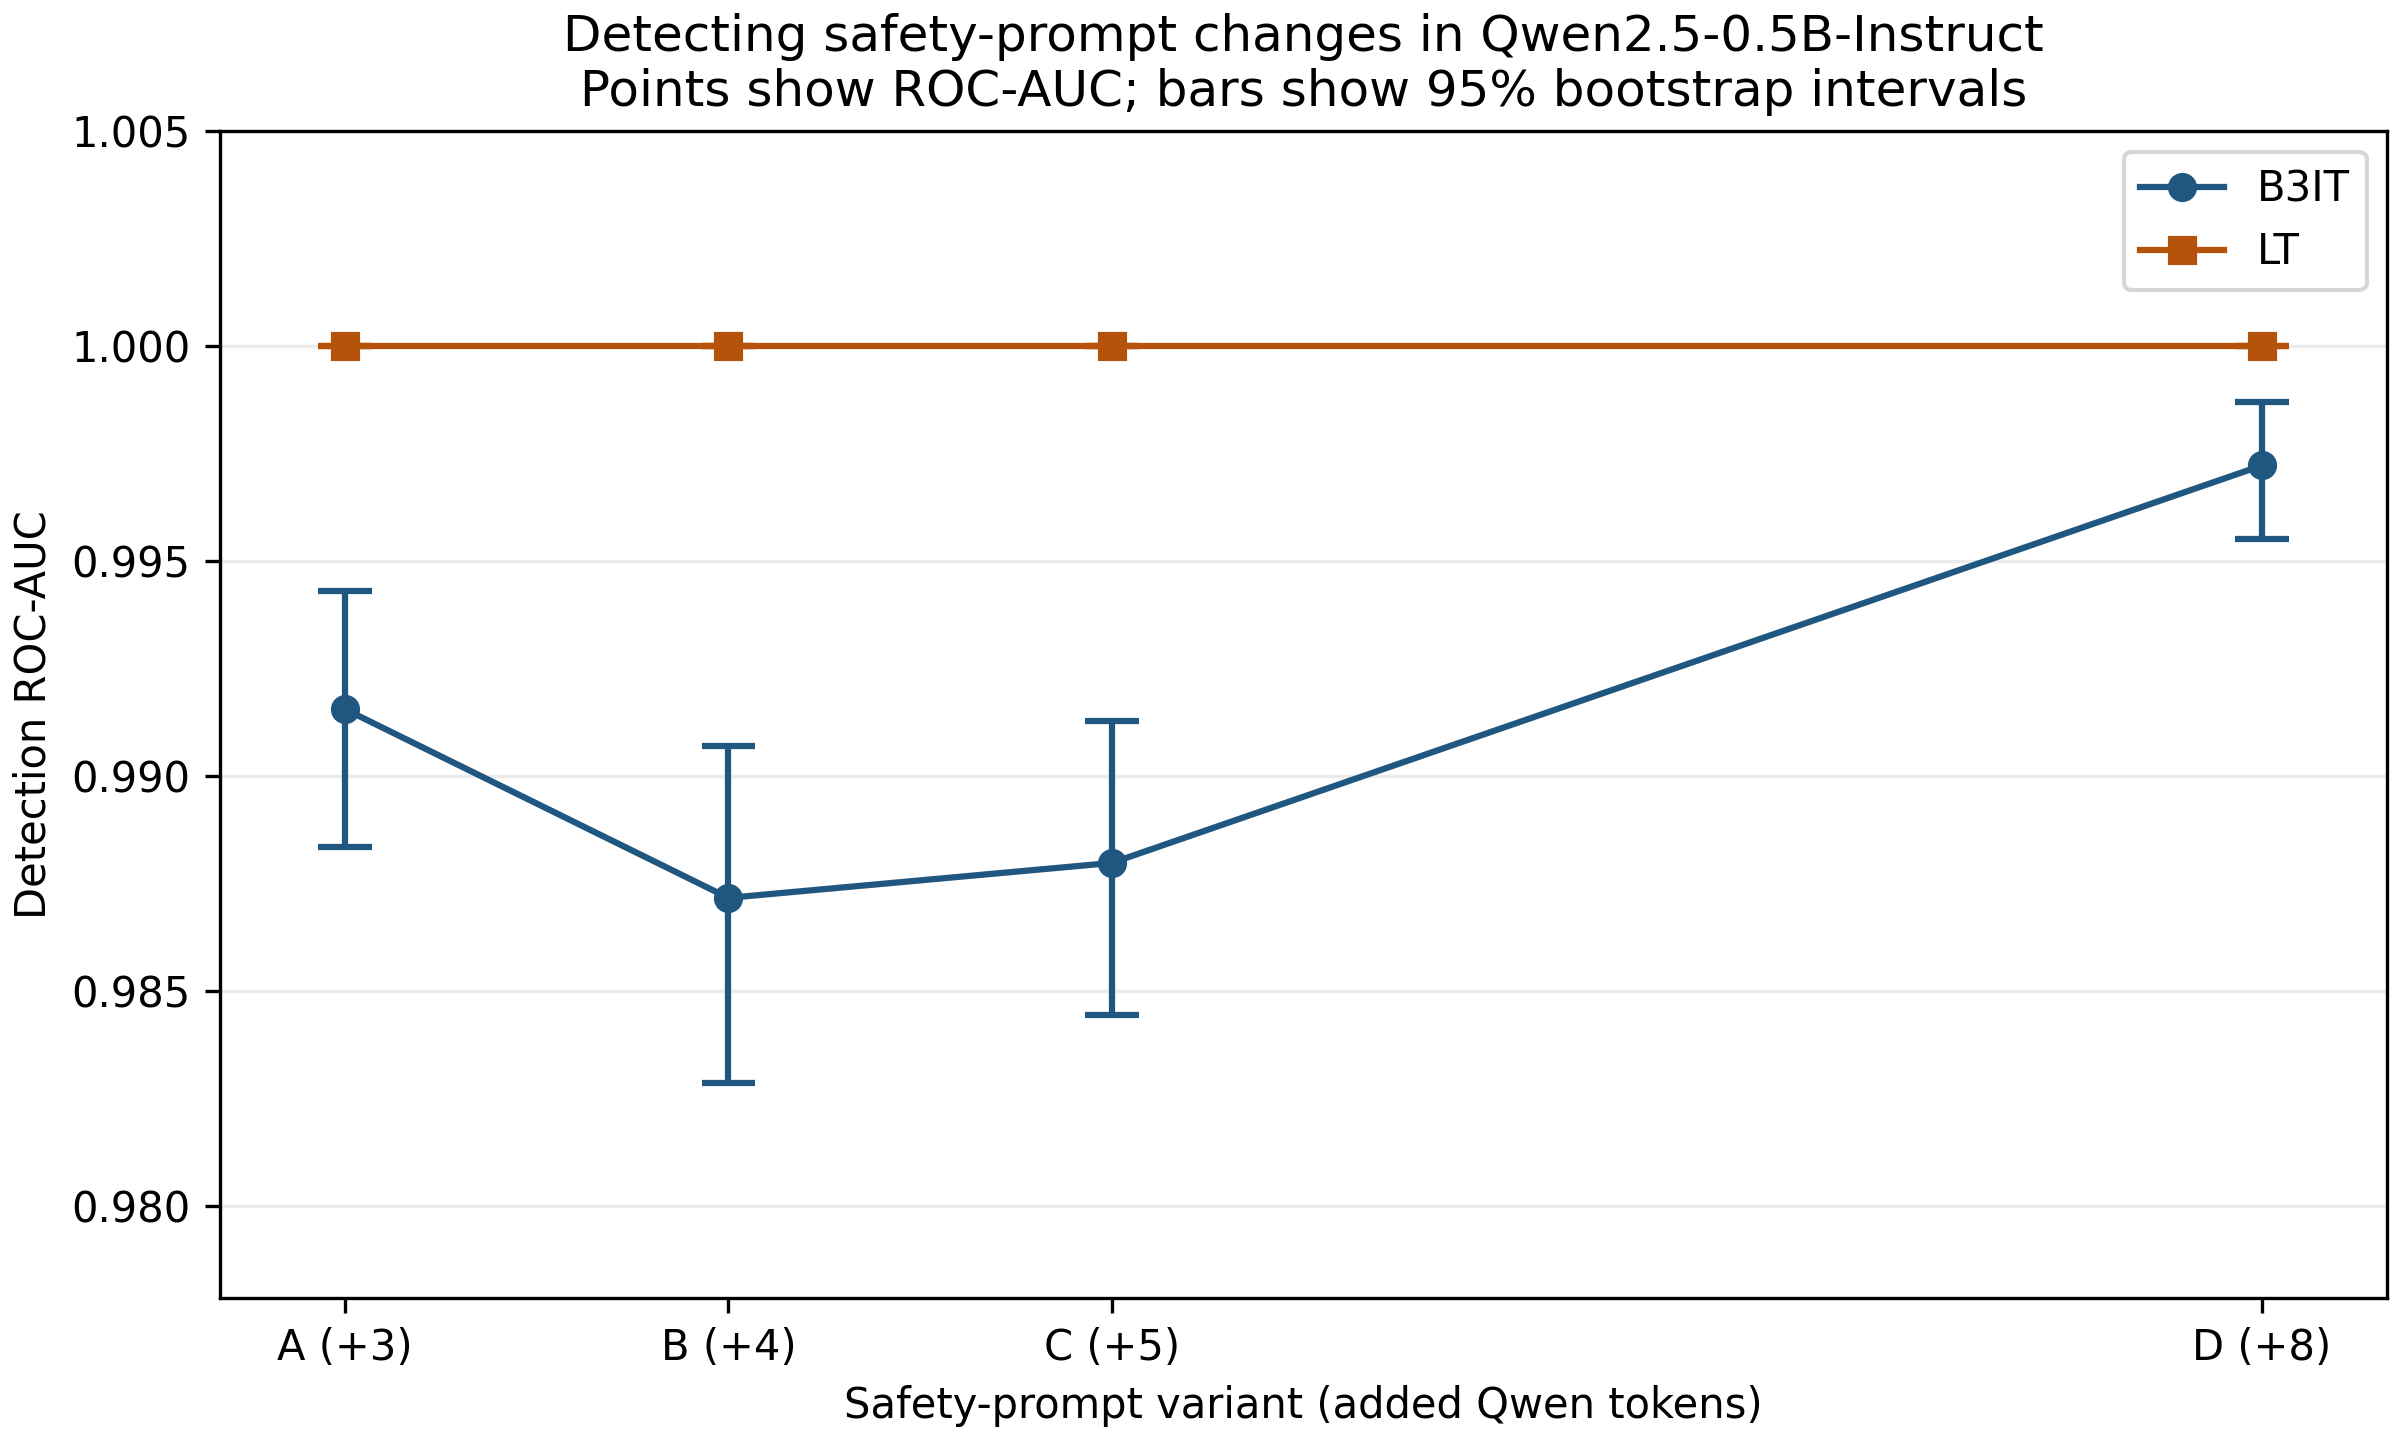

In [29]:
from pathlib import Path
import os
import subprocess
from IPython.display import Image, display

root = Path("/workspace/B3IT_Short_Additions_Fresh")
script = root / "scripts/lt_score_and_plot.py"

script.write_text(r'''
import csv
import gzip
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import orjson
import torch

from track_llm_apis.config import config
from track_llm_apis.tinychange import TinyChange
from track_llm_apis.sampling.common import (
    CompressedOutput, DataSource, SingleVariantResult,
    get_analysis_dir, get_variant_filename,
)
from track_llm_apis.sampling.analyze_param_sweeps import (
    LTParameterSweep, compute_auc_from_stats,
)
from track_llm_apis.util import ci

root = Path(__file__).resolve().parents[1]
collection = root / "results/lt/collection"
out = root / "results/lt/comparison"
out.mkdir(parents=True, exist_ok=True)
config.data_dir = root / "data"
config.analysis.device = "cpu"

# Use the B3IT scores from the corrected run with bootstrap intervals.
with (root / "results/scoring_with_ci/short_prompt_auc_with_ci.csv").open() as f:
    b3it = list(csv.DictReader(f))
assert [(r["variant"], int(r["added_tokens"])) for r in b3it] == [
    ("A", 3), ("B", 4), ("C", 5), ("D", 8)
]
rows = [
    ("B3IT", r["variant"], int(r["added_tokens"]), float(r["roc_auc"]),
     float(r["ci_low"]), float(r["ci_high"]))
    for r in b3it
]

settings = json.loads((collection / "settings.json").read_text())
assert settings["probe"] == config.sampling.logprob.default_prompt == "x"
assert settings["rounds_per_condition"] == 5000
assert settings["checkpoint_rounds"] == 100
assert settings["top_logprobs"] == 20

labels = {"original": TinyChange.unchanged_str()}
for r in b3it:
    labels[r["variant"]] = json.dumps({
        "type": "system_prompt", "label": r["variant"],
        "added_tokens": int(r["added_tokens"]),
    })

# Translate the saved condition label into the format the authors' sweep expects.
data = CompressedOutput(model_name=settings["model"])
for label, repo_label in labels.items():
    for start in range(0, 5000, 100):
        folder = collection / label / f"rounds_{start:04d}"
        file, = folder.glob("*.json.gz")
        with gzip.open(file, "rb") as f:
            raw = orjson.loads(f.read())
        assert raw["references"]["variants"] == [label], file
        raw["references"]["variants"] = [repo_label]
        block = CompressedOutput.from_json(raw)
        assert len(block.rows) == 100, file
        assert all(
            r.prompt[0] == "x" and r.source == DataSource.LT.value
            and r.text[1] == 1 and len(r.first_token_logprobs) >= 20
            for r in block.rows
        ), file
        data.merge(block)
    print(f"Verified {label}: 5000 LT observations", flush=True)

assert len(data.rows) == 25000
random.seed(0)
torch.manual_seed(0)
LTParameterSweep.compute_stats(
    directory=out, data=data, n_samples_values=[10],
    reference_samples_per_prompt=50, n_tests=1000,
)

params = {"detection_samples_per_prompt": 10}
stats_dir = get_analysis_dir(out, DataSource.LT)
draws = {}
random.seed(2026)
for r in b3it:
    label = r["variant"]
    path = stats_dir / get_variant_filename(labels[label], params)
    result = SingleVariantResult.model_validate_json(path.read_bytes())
    h0, h1 = result.h0_stats.stats, result.h1_stats.stats
    assert len(h0) == 2000 and len(h1) == 1000
    auc = compute_auc_from_stats(h0, h1, sampling=False)
    draws[label] = [
        compute_auc_from_stats(h0, h1, sampling=True) for _ in range(250)
    ]
    low, high = ci(draws[label], alpha=0.05)
    rows.append(("LT", label, int(r["added_tokens"]), auc, low, high))
    print(f"{label} (+{r['added_tokens']} tokens) | "
          f"B3IT {float(r['roc_auc']):.4f} | LT {auc:.4f} "
          f"[{low:.4f}, {high:.4f}]", flush=True)

(out / "lt_bootstrap_draws.json").write_text(json.dumps(draws))
with (out / "b3it_vs_lt.csv").open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["method", "variant", "added_tokens", "roc_auc", "ci_low", "ci_high"])
    writer.writerows(rows)

fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
for method, color, marker in [("B3IT", "#205781", "o"), ("LT", "#b45309", "s")]:
    points = [r for r in rows if r[0] == method]
    x = [r[2] for r in points]
    ax.plot(x, [r[3] for r in points], marker=marker, color=color, label=method)
    for _, _, length, _, low, high in points:
        ax.vlines(length, low, high, color=color)
        ax.hlines([low, high], length - 0.07, length + 0.07, color=color)

ax.set_xticks([3, 4, 5, 8], ["A (+3)", "B (+4)", "C (+5)", "D (+8)"])
ax.set(xlabel="Safety-prompt variant (added Qwen tokens)", ylabel="Detection ROC-AUC")
ax.set_ylim(min(r[4] for r in rows) - 0.005, 1.005)
ax.set_title("Detecting safety-prompt changes in Qwen2.5-0.5B-Instruct\n"
             "Points show ROC-AUC; bars show 95% bootstrap intervals")
ax.grid(axis="y", alpha=0.25)
ax.legend()
for ext in ("png", "pdf"):
    fig.savefig(out / f"b3it_vs_lt.{ext}", dpi=300)
plt.close(fig)
print("Saved:", out)
print("LT STEP 3 COMPLETE", flush=True)
''')

env = {
    **os.environ,
    "PYTHONPATH": str(root / "repo/track-llm-apis/src"),
    "MPLBACKEND": "Agg",
}
log = root / "logs/lt_step3_scoring.log"
with log.open("w") as f, subprocess.Popen(
    [str(root / ".venv/bin/python"), "-u", str(script)],
    cwd=root, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
) as process:
    for line in process.stdout:
        print(line, end="", flush=True)
        f.write(line)
        f.flush()
    if process.wait():
        raise RuntimeError(f"LT scoring stopped. See {log}")

display(Image(filename=str(root / "results/lt/comparison/b3it_vs_lt.png")))

LT Step 4 — Verify the saved H0 and H1 scores

In [30]:
from pathlib import Path
from bisect import bisect_left, bisect_right
import csv
import json
import math

root = Path("/workspace/B3IT_Short_Additions_Fresh")
out = root / "results/lt/comparison"

with (out / "b3it_vs_lt.csv").open(newline="") as f:
    reported = {
        r["variant"]: float(r["roc_auc"])
        for r in csv.DictReader(f) if r["method"] == "LT"
    }

checks = {}
for path in sorted((out / "analysis").rglob("*.json")):
    result = json.loads(path.read_text())
    if result.get("params") != {"detection_samples_per_prompt": 10}:
        continue

    label = json.loads(result["variant"])["label"]
    assert label in reported and label not in checks, path
    h0 = sorted(result["h0_stats"]["stats"])
    h1 = sorted(result["h1_stats"]["stats"])
    assert (len(h0), len(h1)) == (2000, 1000), path
    assert all(math.isfinite(x) for x in h0 + h1), path

    # For each changed score, count unchanged scores below it or tied with it.
    wins = sum(bisect_left(h0, x) for x in h1)
    ties = sum(bisect_right(h0, x) - bisect_left(h0, x) for x in h1)
    pairs = len(h0) * len(h1)
    losses = pairs - wins - ties
    auc = (wins + 0.5 * ties) / pairs
    assert math.isclose(auc, reported[label], rel_tol=0, abs_tol=1e-12), label

    gap = min(h1) - max(h0)
    checks[label] = {
        "variant": label, "h0_min": min(h0), "h0_max": max(h0),
        "h1_min": min(h1), "h1_max": max(h1), "gap": gap,
        "tied_pairs": ties, "reversed_pairs": losses, "auc": auc,
    }
    print(f"{label} | max H0 {max(h0):.8g} | min H1 {min(h1):.8g} | "
          f"gap {gap:+.8g} | ties {ties} | reversed {losses} | AUC {auc:.9f}")

assert set(checks) == {"A", "B", "C", "D"}, "Expected four LT score files."
dest = out / "lt_score_sanity_check.csv"
with dest.open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=checks["A"].keys())
    writer.writeheader()
    writer.writerows(checks[label] for label in "ABCD")
print("Saved:", dest)

A | max H0 0.034535937 | min H1 0.19281225 | gap +0.15827631 | ties 0 | reversed 0 | AUC 1.000000000
B | max H0 0.034535937 | min H1 0.27596578 | gap +0.24142984 | ties 0 | reversed 0 | AUC 1.000000000
C | max H0 0.039429877 | min H1 0.17547671 | gap +0.13604684 | ties 0 | reversed 0 | AUC 1.000000000
D | max H0 0.037065297 | min H1 0.37072986 | gap +0.33366457 | ties 0 | reversed 0 | AUC 1.000000000
Saved: /workspace/B3IT_Short_Additions_Fresh/results/lt/comparison/lt_score_sanity_check.csv


In [34]:
%%script env MPLBACKEND=Agg /workspace/B3IT_Short_Additions_Fresh/.venv/bin/python -u
from pathlib import Path
from bisect import bisect_left, bisect_right
import csv
import json
import math
import matplotlib.pyplot as plt

out = Path("/workspace/B3IT_Short_Additions_Fresh/results/lt/comparison")
with (out / "b3it_vs_lt.csv").open(newline="") as f:
    rows = list(csv.DictReader(f))

reported = {r["variant"]: float(r["roc_auc"]) for r in rows if r["method"] == "LT"}
checks = {}

for path in (out / "analysis").rglob("*.json"):
    result = json.loads(path.read_text())
    if result.get("params") != {"detection_samples_per_prompt": 10}:
        continue
    label = json.loads(result["variant"])["label"]
    assert label in reported and label not in checks, path

    h0 = sorted(result["h0_stats"]["stats"])   # No-change scores
    h1 = result["h1_stats"]["stats"]           # Change scores
    assert (len(h0), len(h1)) == (2000, 1000), path
    assert all(math.isfinite(x) for x in h0 + h1), path

    # AUC counts how often a change score ranks higher, with half credit for ties.
    wins = sum(bisect_left(h0, x) for x in h1)
    ties = sum(bisect_right(h0, x) - bisect_left(h0, x) for x in h1)
    auc = (wins + 0.5 * ties) / (len(h0) * len(h1))
    assert math.isclose(auc, reported[label], rel_tol=0, abs_tol=1e-12), label
    checks[label] = (auc, max(h0), min(h1))

assert set(checks) == set("ABCD")
print("Variant     ROC-AUC      Highest no-change   Lowest change   Every change higher?")
for label in "ABCD":
    auc, highest_no_change, lowest_change = checks[label]
    answer = "Yes" if lowest_change > highest_no_change else "No"
    print(f"{label:7}   {auc:.8f}   {highest_no_change:17.8f}   "
          f"{lowest_change:13.8f}   {answer}")

fig, ax = plt.subplots(figsize=(8, 5))
for method, color, marker in [("B3IT", "#205781", "o"), ("LT", "#b45309", "s")]:
    points = sorted((r for r in rows if r["method"] == method),
                    key=lambda r: int(r["added_tokens"]))
    x = [int(r["added_tokens"]) for r in points]
    ax.plot(x, [float(r["roc_auc"]) for r in points],
            marker=marker, color=color, label=method)

ax.set_xticks([3, 4, 5, 8], ["A (+3)", "B (+4)", "C (+5)", "D (+8)"])
ax.set(xlabel="Safety-prompt variant (added Qwen tokens)", ylabel="Detection ROC-AUC",
       title="Detecting safety-prompt changes in Qwen2.5-0.5B-Instruct")
ax.set_ylim(min(float(r["ci_low"]) for r in rows) - 0.004, 1.002)
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.subplots_adjust(bottom=0.30)

caption = (
    "Per detection test, B3IT used 15 generated tokens (5 probes × 3). LT used 10 generated\n"
    "tokens (1 probe × 10) with access to the top-20 log probabilities for each response.\n"
    "Both used 50 reference observations per probe. Bars show 95% bootstrap confidence intervals."
)
fig.text(0.08, 0.035, caption, fontsize=9, va="bottom")
for ext in ("png", "pdf"):
    fig.savefig(out / f"b3it_vs_lt_captioned.{ext}", dpi=300, bbox_inches="tight")
plt.show()
print("Saved captioned PNG and PDF in", out)

Variant     ROC-AUC      Highest no-change   Lowest change   Every change higher?
A         1.00000000          0.03453594      0.19281225   Yes
B         1.00000000          0.03453594      0.27596578   Yes
C         1.00000000          0.03942988      0.17547671   Yes
D         1.00000000          0.03706530      0.37072986   Yes
Saved captioned PNG and PDF in /workspace/B3IT_Short_Additions_Fresh/results/lt/comparison
